<a href="https://colab.research.google.com/github/samirapilfree5-creator/Code-sql/blob/main/TP_4_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TP 4 — Modélisation de données de santé : images de cancer oral**




## Préparation



In [ ]:
# ============================ Imports et configuration ============================
import os, glob, random, subprocess, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
from tqdm.auto import tqdm
import cv2
from skimage.measure import shannon_entropy

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import StandardScaler
from sklearn.utils.class_weight import compute_class_weight
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix, silhouette_score)
from sklearn.metrics.pairwise import linear_kernel, polynomial_kernel, rbf_kernel

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
cv2.setRNGSeed(SEED)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

print("TensorFlow :", tf.__version__, "| OpenCV :", cv2.__version__)
print("GPU détecté :", bool(tf.config.list_physical_devices("GPU")), "(non nécessaire pour ce TP)")

TensorFlow : 2.21.0 | OpenCV : 5.0.0
GPU détecté : False (non nécessaire pour ce TP)


In [ ]:
# ============ Téléchargement du jeu de données (dépôt GitHub fourni dans le sujet) ============
# On ne récupère que le dossier "lab3/data" (clonage partiel) pour aller plus vite.
REPO_URL    = "https://github.com/EDJINEDJA/Health-Data-modelling.git"
REPO_DIR    = "Health-Data-modelling"
DATA_SUBDIR = os.path.join("lab3", "data", "Oral Cancer", "Oral Cancer Dataset")
DATA_DIR    = os.path.join(REPO_DIR, DATA_SUBDIR)

if not os.path.isdir(DATA_DIR):
    subprocess.run(["git", "clone", "--depth", "1", "--filter=blob:none", "--sparse", REPO_URL, REPO_DIR], check=True)
    subprocess.run(["git", "-C", REPO_DIR, "sparse-checkout", "set", "lab3/data"], check=True)

print("Dossier des données :", DATA_DIR)
print("Sous-dossiers (= étiquettes) :", sorted(os.listdir(DATA_DIR)))

Dossier des données : Health-Data-modelling/lab3/data/Oral Cancer/Oral Cancer Dataset
Sous-dossiers (= étiquettes) : ['CANCER', 'NON CANCER']


## Section 1 — Comprendre et transformer les images


### **Q1 — Structurer la dataset**

Construire une table avec deux colonnes :

- `image_path` : chemin relatif ou absolu vers l'image ;
- `label` : `1` pour cancer oral et `0` pour absence de cancer.


Images illisibles : 0
Forme du tableau : (750, 2)


,image_path,label
0,Health-Data-modelling/lab3/data/Oral Cancer/Or...,1
1,Health-Data-modelling/lab3/data/Oral Cancer/Or...,1
2,Health-Data-modelling/lab3/data/Oral Cancer/Or...,1
3,Health-Data-modelling/lab3/data/Oral Cancer/Or...,1
4,Health-Data-modelling/lab3/data/Oral Cancer/Or...,1


,image_path,label
745,Health-Data-modelling/lab3/data/Oral Cancer/Or...,0
746,Health-Data-modelling/lab3/data/Oral Cancer/Or...,0
747,Health-Data-modelling/lab3/data/Oral Cancer/Or...,0
748,Health-Data-modelling/lab3/data/Oral Cancer/Or...,0
749,Health-Data-modelling/lab3/data/Oral Cancer/Or...,0



Effectifs par classe :
  label 0 (NON CANCER) : 250  (33.3%)
  label 1 (CANCER)     : 500  (66.7%)


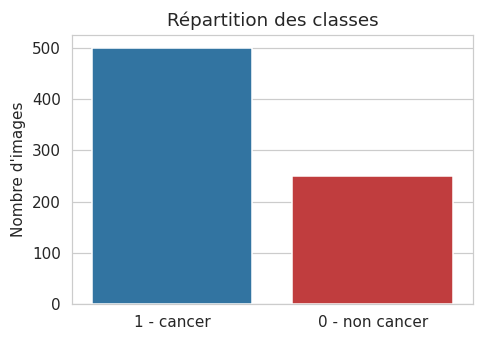

In [ ]:
# Correspondance dossier -> étiquette demandée par l'énoncé
LABEL_MAP = {"CANCER": 1, "NON CANCER": 0}
VALID_EXT = (".jpg", ".jpeg", ".png")

rows = []
for folder, label in LABEL_MAP.items():
    folder_path = os.path.join(DATA_DIR, folder)
    assert os.path.isdir(folder_path), f"Dossier introuvable : {folder_path}"
    for path in sorted(glob.glob(os.path.join(folder_path, "*"))):
        if path.lower().endswith(VALID_EXT):
            rows.append({"image_path": path, "label": label})

df = pd.DataFrame(rows, columns=["image_path", "label"])

# Contrôle de lisibilité (lecture de l'en-tête uniquement, rapide)
corrupted = []
for p in df["image_path"]:
    try:
        with Image.open(p) as im:
            im.verify()
    except Exception:
        corrupted.append(p)
print(f"Images illisibles : {len(corrupted)}")

print(f"Forme du tableau : {df.shape}")
display(df.head())
display(df.tail())

counts = df["label"].value_counts().sort_index()
print("\nEffectifs par classe :")
print(f"  label 0 (NON CANCER) : {counts[0]}  ({counts[0]/len(df):.1%})")
print(f"  label 1 (CANCER)     : {counts[1]}  ({counts[1]/len(df):.1%})")

fig, ax = plt.subplots(figsize=(4.5, 3.2))
sns.countplot(x=df["label"].map({0: "0 - non cancer", 1: "1 - cancer"}), ax=ax, palette=["#1f77b4", "#d62728"])
ax.set_xlabel(""); ax.set_ylabel("Nombre d'images"); ax.set_title("Répartition des classes")
plt.tight_layout(); plt.show()

Observations: Le tableau contient une ligne par image avec `image_path` et `label` (1 = cancer, 0 = non cancer).

Le dépôt contient **500 images cancer et 250 non-cancer** (et non 450 comme dans l'énoncé) : les classes sont déséquilibrées à 2 pour 1.  

### **Q2 — Visualisation de neuf images cancéreuses**



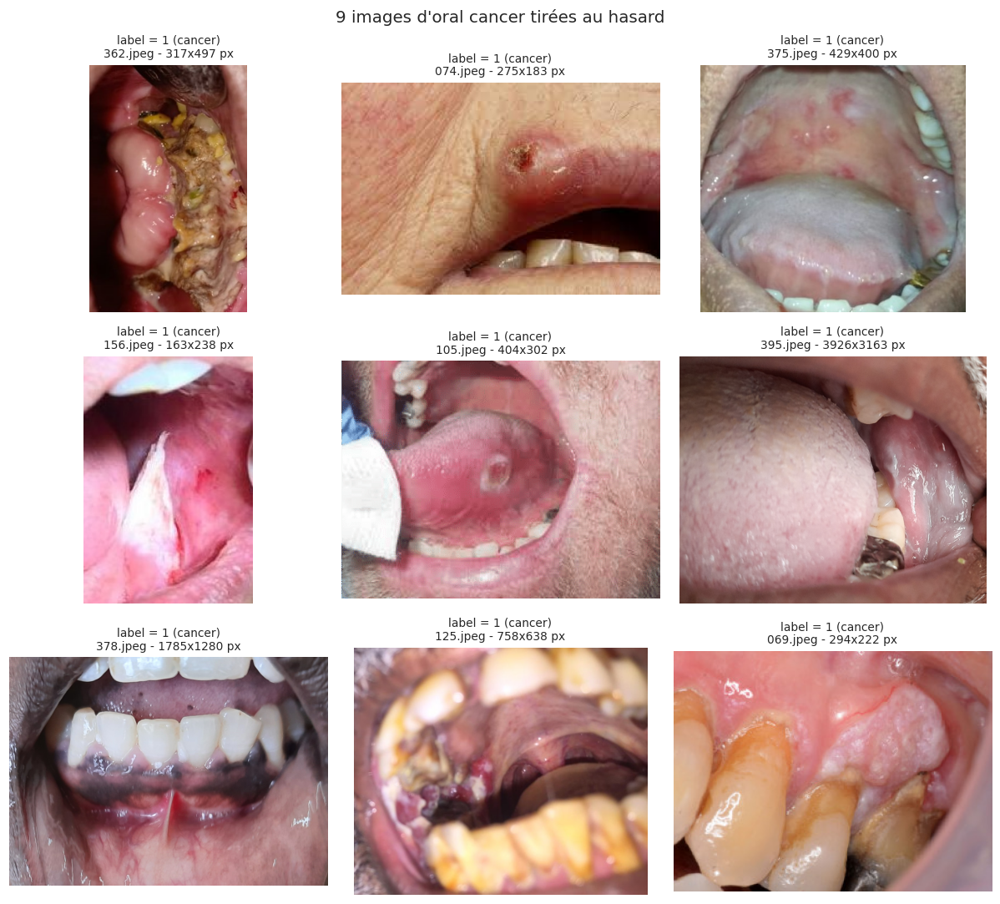

In [ ]:
cancer_df = df[df["label"] == 1]
sample9 = cancer_df.sample(9, random_state=SEED)

fig, axes = plt.subplots(3, 3, figsize=(11, 10))
for ax, (_, row) in zip(axes.ravel(), sample9.iterrows()):
    img = Image.open(row["image_path"]).convert("RGB")
    ax.imshow(img)
    ax.set_title(f"label = {row['label']} (cancer)\n{os.path.basename(row['image_path'])} - {img.size[0]}x{img.size[1]} px", fontsize=9)
    ax.axis("off")
plt.suptitle("9 images d'oral cancer tirées au hasard", fontsize=13)
plt.tight_layout(); plt.show()

**Observations** Les images sont très hétérogènes (cadrage, éclairage, résolution, ratio d'aspect) : il faudra les redimensionner avant de les aplatir (Q7).

### **Q3 — Décomposition d'une image selon quatre représentations**

Afficher une image cancéreuse selon les canaux rouge, vert, bleu et niveaux de gris.


Image : 362.jpeg
Forme de l'image RGB : (497, 317, 3) -> (hauteur, largeur, 3 canaux)
Forme d'un canal     : (497, 317) | type : uint8 | plage : 0 à 255


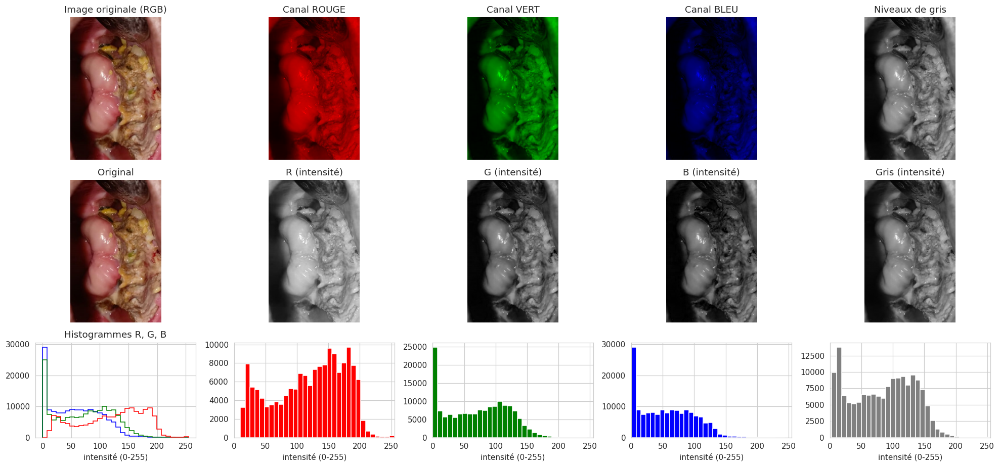

In [ ]:
demo_path = sample9.iloc[0]["image_path"]          # une image de cancer prise parmi les 9 de Q2
img = np.array(Image.open(demo_path).convert("RGB"))
R, G, B = img[..., 0], img[..., 1], img[..., 2]
gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)

print("Image :", os.path.basename(demo_path))
print("Forme de l'image RGB :", img.shape, "-> (hauteur, largeur, 3 canaux)")
print("Forme d'un canal     :", R.shape, "| type :", R.dtype, "| plage :", img.min(), "à", img.max())

def only_channel(rgb, c):
    out = np.zeros_like(rgb); out[..., c] = rgb[..., c]; return out

panels = [("Image originale (RGB)", img, None),
          ("Canal ROUGE", only_channel(img, 0), None),
          ("Canal VERT", only_channel(img, 1), None),
          ("Canal BLEU", only_channel(img, 2), None),
          ("Niveaux de gris", gray, "gray")]

fig, axes = plt.subplots(3, 5, figsize=(18, 8.5), gridspec_kw={"height_ratios": [3, 3, 2]})
for j, (title, arr, cmap) in enumerate(panels):
    axes[0, j].imshow(arr, cmap=cmap); axes[0, j].set_title(title); axes[0, j].axis("off")

# 2e ligne : intensités des canaux (en gris) pour bien voir la matrice 2D de chaque canal
axes[1, 0].imshow(img); axes[1, 0].set_title("Original"); axes[1, 0].axis("off")
for j, (name, ch) in enumerate([("R (intensité)", R), ("G (intensité)", G), ("B (intensité)", B)], start=1):
    axes[1, j].imshow(ch, cmap="gray", vmin=0, vmax=255); axes[1, j].set_title(name); axes[1, j].axis("off")
axes[1, 4].imshow(gray, cmap="gray", vmin=0, vmax=255); axes[1, 4].set_title("Gris (intensité)"); axes[1, 4].axis("off")

# 3e ligne : histogrammes
axes[2, 0].hist([R.ravel(), G.ravel(), B.ravel()], bins=32, color=["r", "g", "b"], histtype="step")
axes[2, 0].set_title("Histogrammes R, G, B")
for j, (ch, col) in enumerate([(R, "r"), (G, "g"), (B, "b"), (gray, "gray")], start=1):
    axes[2, j].hist(ch.ravel(), bins=32, color=col); axes[2, j].set_xlim(0, 255)
for ax in axes[2]:
    ax.set_xlabel("intensité (0-255)")
plt.tight_layout(); plt.show()

**Observations** Le canal rouge est le plus lumineux (moyennes d'environ 0,62 en R, 0,48 en V et 0,43 en B sur l'ensemble du jeu). Les trois canaux sont fortement corrélés ; la couleur se lit dans leurs écarts. Le niveau de gris ($0{,}299R+0{,}587G+0{,}114B$) garde la luminosité mais **perd la couleur**, pourtant cliniquement utile (rougeur, plages blanchâtres).

### **Q4 — Étude comparative de prétraitements**

Au lieu d'appliquer une seule chaîne de traitements à une seule image, nous avons coisi de comparer plusieurs pipelines sur trois images cancéreuses différentes. Le but est d'identifier les compromis entre réduction du bruit, contraste, netteté, contours et segmentation.


In [ ]:
# ============================================================
# Q4 — Sélection de trois images et fonctions de prétraitement
# ============================================================
from pathlib import Path

rng_q4 = np.random.default_rng(SEED + 4)
candidate_paths_q4 = list(cancer_df["image_path"])
selected_paths_q4 = rng_q4.choice(candidate_paths_q4, size=3, replace=False)

def resize_for_q4(image, max_size=512):
    """Réduit les très grandes images sans agrandir les petites."""
    h, w = image.shape[:2]
    scale = min(1.0, max_size / max(h, w))
    if scale < 1:
        return cv2.resize(image, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    return image

def unsharp_mask_q4(image, sigma=2.0, amount=1.0):
    """Accentue les détails par masque flou, avec limitation des valeurs."""
    blurred = cv2.GaussianBlur(image, (0, 0), sigmaX=sigma)
    return np.clip(cv2.addWeighted(image, 1 + amount, blurred, -amount, 0), 0, 255).astype(np.uint8)

def clahe_rgb_q4(image, clip_limit=2.0, tile_grid=(8, 8)):
    """Améliore la luminance dans l'espace Lab sans modifier directement les couleurs."""
    lab_img = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    L, A, B = cv2.split(lab_img)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    return cv2.cvtColor(cv2.merge([clahe.apply(L), A, B]), cv2.COLOR_LAB2RGB)

def otsu_q4(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    smooth = cv2.GaussianBlur(gray, (5, 5), 0)
    threshold, binary = cv2.threshold(smooth, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return binary, threshold

def kmeans_red_mask_q4(image, k=3):
    """Segmente approximativement les zones rouges dans l'espace Lab."""
    lab_img = cv2.cvtColor(image, cv2.COLOR_RGB2LAB)
    pixels = lab_img.reshape(-1, 3).astype(np.float32)
    criteria = (cv2.TERM_CRITERIA_EPS + cv2.TERM_CRITERIA_MAX_ITER, 30, 0.5)
    _, labels, centers = cv2.kmeans(pixels, k, None, criteria, 5, cv2.KMEANS_PP_CENTERS)
    labels = labels.reshape(image.shape[:2])
    segmented = cv2.cvtColor(centers.astype(np.uint8)[labels], cv2.COLOR_LAB2RGB)
    red_cluster = int(np.argmax(centers[:, 1]))
    mask = (labels == red_cluster).astype(np.uint8) * 255
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (7, 7))
    mask = cv2.morphologyEx(mask, cv2.MORPH_OPEN, kernel)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel)
    return segmented, mask

def build_q4_pipelines(image):
    bilateral = cv2.bilateralFilter(image, d=9, sigmaColor=60, sigmaSpace=60)
    clahe = clahe_rgb_q4(image)
    bilateral_clahe = clahe_rgb_q4(bilateral)
    bilateral_clahe_sharp = unsharp_mask_q4(bilateral_clahe, sigma=2.0, amount=1.0)
    otsu_img, threshold = otsu_q4(image)
    segmented, red_mask = kmeans_red_mask_q4(image)
    return {
        "P0 — originale": image,
        "P1 — filtre bilatéral": bilateral,
        "P2 — CLAHE seul": clahe,
        "P3 — bilatéral + CLAHE": bilateral_clahe,
        "P4 — bilatéral + CLAHE + netteté": bilateral_clahe_sharp,
        "P5 — niveaux de gris + Otsu": otsu_img,
        "P6 — K-means Lab": segmented,
        "P7 — masque des zones rouges": red_mask,
    }, threshold

def metrics_q4(image):
    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY) if image.ndim == 3 else image
    edges = cv2.Canny(gray, 50, 150)
    return {
        "contraste (écart-type)": gray.std(),
        "netteté (variance Laplacien)": cv2.Laplacian(gray, cv2.CV_64F).var(),
        "densité des contours": (edges > 0).mean(),
        "entropie": shannon_entropy(gray),
        "intensité moyenne": gray.mean(),
    }

print("Images retenues pour Q4 :")
for p in selected_paths_q4:
    print(" -", Path(p).name)


Images retenues pour Q4 :
 - 110.jpeg
 - 452.jpeg
 - 251.jpeg


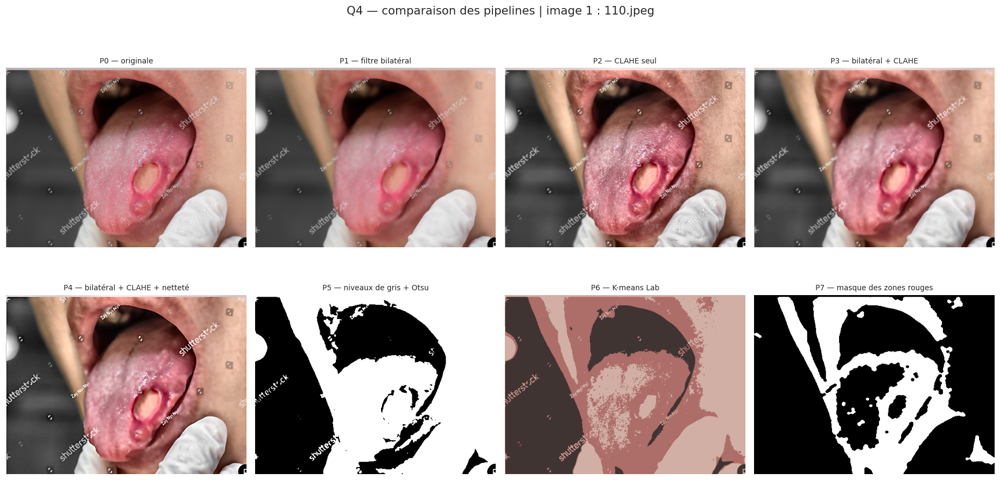

Image 1 : taille (382, 512, 3) | seuil d'Otsu = 114.0


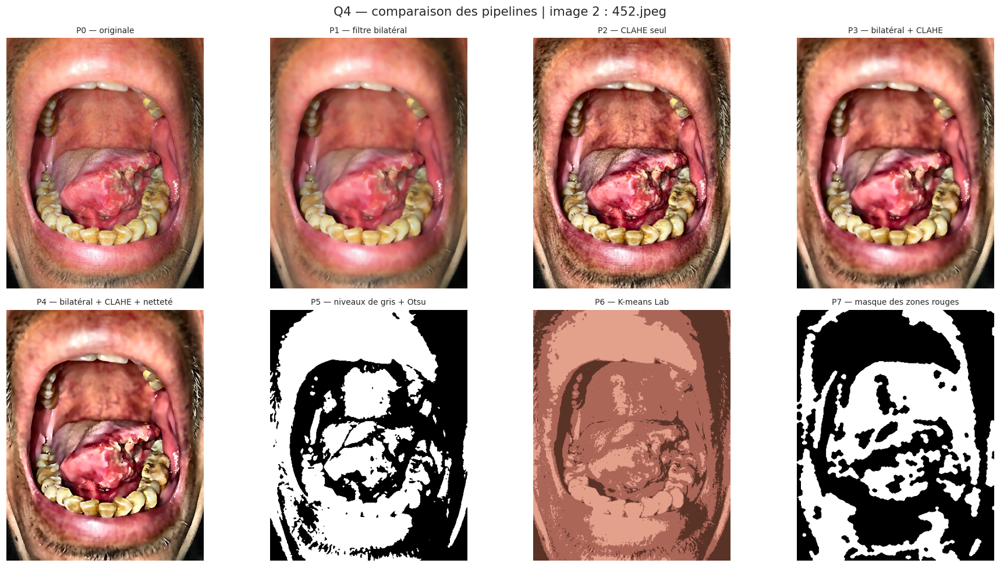

Image 2 : taille (490, 385, 3) | seuil d'Otsu = 123.0


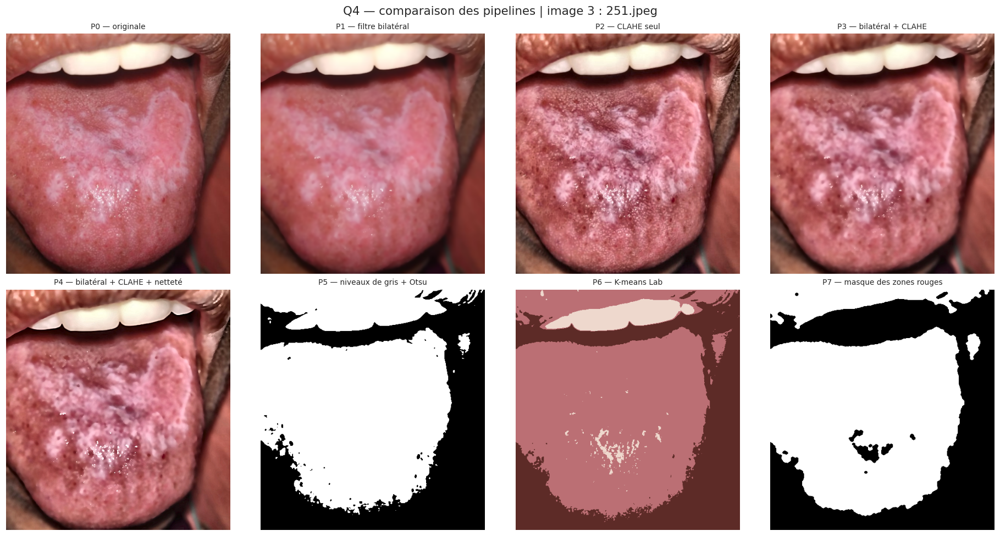

Image 3 : taille (512, 477, 3) | seuil d'Otsu = 104.0
Indicateurs calculés pour chaque résultat :


,contraste (écart-type),netteté (variance Laplacien),densité des contours,entropie,intensité moyenne,image,pipeline
0,56.508,322.597,0.047,7.559,123.593,Image 1,P0 — originale
1,56.174,290.811,0.027,7.526,123.521,Image 1,P1 — filtre bilatéral
2,58.240,746.961,0.113,7.725,125.334,Image 1,P2 — CLAHE seul
3,58.587,495.722,0.040,7.717,126.740,Image 1,P3 — bilatéral + CLAHE
4,61.183,1713.835,0.056,7.803,126.774,Image 1,P4 — bilatéral + CLAHE + netteté
5,125.414,6553.567,0.022,0.976,150.468,Image 1,P5 — niveaux de gris + Otsu
6,52.775,1290.833,0.052,1.585,123.542,Image 1,P6 — K-means Lab
7,115.942,6017.299,0.023,0.871,74.455,Image 1,P7 — masque des zones rouges
8,45.337,363.935,0.134,7.513,125.709,Image 2,P0 — originale
9,44.354,154.341,0.054,7.477,125.713,Image 2,P1 — filtre bilatéral


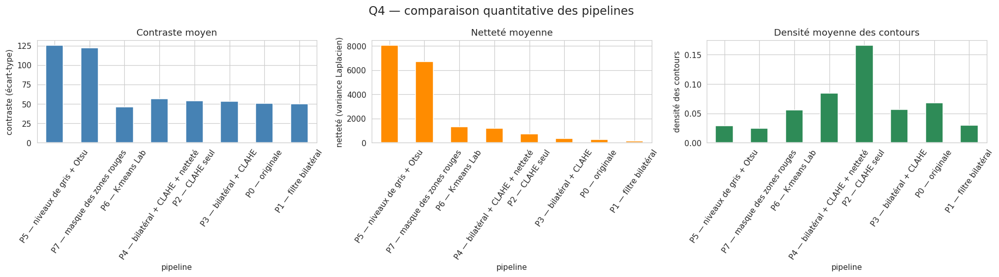

,contraste (écart-type),netteté (variance Laplacien),densité des contours,entropie
pipeline,,,,
P5 — niveaux de gris + Otsu,125.556,8060.060,0.029,0.978
P7 — masque des zones rouges,122.390,6687.141,0.025,0.943
P6 — K-means Lab,46.188,1317.435,0.056,1.427
P4 — bilatéral + CLAHE + netteté,56.372,1197.649,0.085,7.757
P2 — CLAHE seul,54.147,738.765,0.166,7.700
P3 — bilatéral + CLAHE,53.597,347.080,0.056,7.679
P0 — originale,50.355,247.476,0.068,7.521
P1 — filtre bilatéral,49.791,157.692,0.030,7.489


In [ ]:
# ============================================================
# Q4 — Affichage comparatif et analyse quantitative
# ============================================================
all_metrics_q4 = []

for image_number, path in enumerate(selected_paths_q4, start=1):
    original = resize_for_q4(np.asarray(Image.open(path).convert("RGB")))
    pipelines, otsu_threshold = build_q4_pipelines(original)

    fig, axes = plt.subplots(2, 4, figsize=(17, 9))
    for ax, (name, processed) in zip(axes.ravel(), pipelines.items()):
        ax.imshow(processed, cmap="gray" if processed.ndim == 2 else None)
        ax.set_title(name, fontsize=9)
        ax.axis("off")
        values = metrics_q4(processed)
        values.update({"image": f"Image {image_number}", "pipeline": name})
        all_metrics_q4.append(values)

    plt.suptitle(f"Q4 — comparaison des pipelines | image {image_number} : {Path(path).name}", fontsize=14)
    plt.tight_layout()
    plt.show()
    print(f"Image {image_number} : taille {original.shape} | seuil d'Otsu = {otsu_threshold:.1f}")

metrics_q4_df = pd.DataFrame(all_metrics_q4)
print("Indicateurs calculés pour chaque résultat :")
display(metrics_q4_df.round(3))

mean_metrics_q4 = metrics_q4_df.groupby("pipeline")[[
    "contraste (écart-type)", "netteté (variance Laplacien)",
    "densité des contours", "entropie"
]].mean().sort_values("netteté (variance Laplacien)", ascending=False)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, column, color, title in zip(
    axes,
    ["contraste (écart-type)", "netteté (variance Laplacien)", "densité des contours"],
    ["steelblue", "darkorange", "seagreen"],
    ["Contraste moyen", "Netteté moyenne", "Densité moyenne des contours"]
):
    mean_metrics_q4[column].plot(kind="bar", ax=ax, color=color, title=title)
    ax.tick_params(axis="x", rotation=55)
    ax.set_ylabel(column)
plt.suptitle("Q4 — comparaison quantitative des pipelines", fontsize=15)
plt.tight_layout()
plt.show()

display(mean_metrics_q4.round(3))


In [ ]:
# Cellule volontairement conservée comme espace d'analyse complémentaire.
# Les résultats de Q4 sont déjà regroupés dans metrics_q4_df et mean_metrics_q4.


### **Observation Q4**

Les trois images ne réagissent pas de la même manière aux traitements. Le filtre bilatéral réduit le bruit tout en préservant mieux les contours qu'un filtre gaussien classique. Le CLAHE augmente le contraste local, ce qui peut être utile sur une image sombre, mais il peut aussi amplifier le bruit s'il est trop agressif. La combinaison bilatéral + CLAHE constitue donc un compromis intéressant. L'ajout du masque flou augmente la netteté mesurée par la variance du Laplacien, mais une valeur excessive peut produire des halos artificiels. Otsu est davantage adapté à la production d'un masque binaire qu'à la conservation des détails visuels. La segmentation K-means dans l'espace Lab permet d'explorer les zones rouges, mais elle reste sensible à l'éclairage et ne constitue pas un outil diagnostique.

Les indicateurs numériques servent à comparer les transformations, mais ils ne suffisent pas à définir une « meilleure » image : une hausse de la netteté ou de l'entropie peut aussi correspondre à une amplification du bruit. Dans cette étude, le pipeline à retenir dépend donc de l'objectif : bilatéral + CLAHE pour améliorer la visualisation, masque d'Otsu pour une segmentation simple, et K-means Lab pour explorer la couleur.


### **Q5 — Superposer une image cancéreuse et une image non cancéreuse**

Avant de superposer, nos imaes n'ayant pas les mêmes tailles, un redimensionnement, rendant les deux images à la même forme puis calcul d'une moyenne pondérée pixel à pixel afin d'obtenir un overlay.


Formes : (384, 384, 3) (384, 384, 3) -> identiques, les opérations pixel à pixel sont possibles


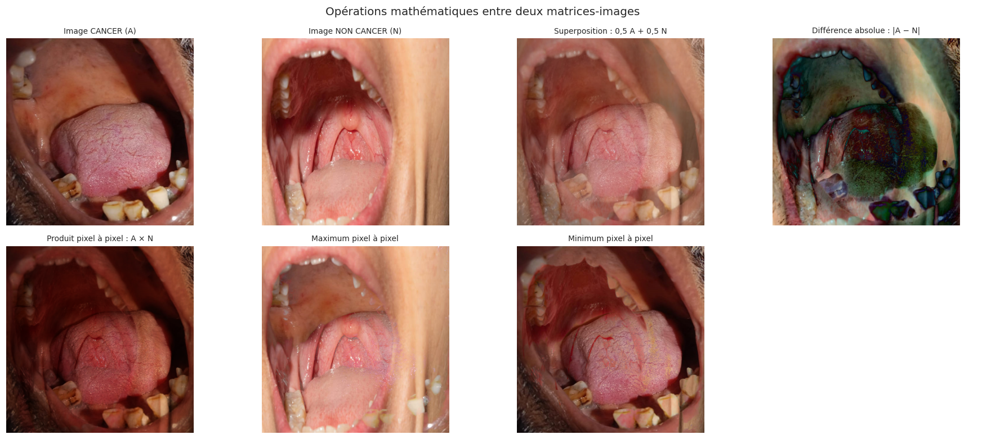

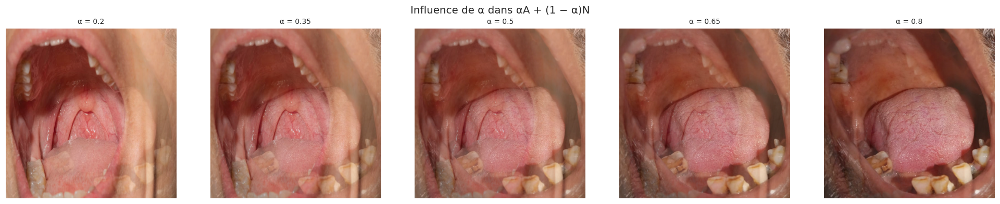

In [ ]:
# ============================================================
# Q5 — Opérations mathématiques entre une image cancer
#      et une image non-cancer
# ============================================================

# Fonction locale d'affichage.
# Elle est définie dans Q5 afin que cette cellule reste autonome,
# même si la cellule Q4 n'a pas été exécutée.
def show_grid(images, titles, ncols=4, figsize=None, suptitle=None):
    n = len(images)
    nrows = int(np.ceil(n / ncols))

    if figsize is None:
        figsize = (4.2 * ncols, 3.6 * nrows)

    fig, axes = plt.subplots(
        nrows,
        ncols,
        figsize=figsize,
        squeeze=False
    )

    axes = axes.ravel()

    # Masquer toutes les cases inutilisées
    for ax in axes:
        ax.axis("off")

    # Afficher les images et leurs titres
    for ax, image, title in zip(axes, images, titles):
        if image.ndim == 2:
            ax.imshow(image, cmap="gray")
        else:
            ax.imshow(image)

        ax.set_title(title, fontsize=9)
        ax.axis("off")

    if suptitle is not None:
        fig.suptitle(suptitle, fontsize=13)

    plt.tight_layout()
    plt.show()


# Taille commune pour permettre les opérations pixel à pixel
SZ = (384, 384)

# Sélection reproductible d'une image cancer et d'une image non-cancer
p_cancer = (
    df[df["label"] == 1]
    .sample(1, random_state=7)["image_path"]
    .iloc[0]
)

p_non_cancer = (
    df[df["label"] == 0]
    .sample(1, random_state=7)["image_path"]
    .iloc[0]
)

# Chargement et conversion en RGB
A_img = np.asarray(
    Image.open(p_cancer)
    .convert("RGB")
    .resize(SZ, Image.LANCZOS)
)

N_img = np.asarray(
    Image.open(p_non_cancer)
    .convert("RGB")
    .resize(SZ, Image.LANCZOS)
)

print(
    "Formes :",
    A_img.shape,
    N_img.shape,
    "-> identiques, les opérations pixel à pixel sont possibles"
)

# Vérification de sécurité
assert A_img.shape == N_img.shape
assert A_img.ndim == 3
assert A_img.shape[2] == 3

# ------------------------------------------------------------
# Opérations mathématiques pixel à pixel
# ------------------------------------------------------------

# Moyenne pondérée :
# overlay = alpha * A + (1-alpha) * N
alpha = 0.5

overlay_05 = cv2.addWeighted(
    A_img,
    alpha,
    N_img,
    1 - alpha,
    0
)

# Différence absolue : |A - N|
diff_abs = cv2.absdiff(A_img, N_img)

# Produit normalisé :
# les deux images sont ramenées dans [0, 1]
# avant la multiplication
product = (
    (A_img.astype(np.float32) / 255.0)
    * (N_img.astype(np.float32) / 255.0)
    * 255.0
).clip(0, 255).astype(np.uint8)

# Maximum et minimum pixel par pixel
maxi = np.maximum(A_img, N_img)
mini = np.minimum(A_img, N_img)

# ------------------------------------------------------------
# Affichage des opérations
# ------------------------------------------------------------

images_q5 = [
    A_img,
    N_img,
    overlay_05,
    diff_abs,
    product,
    maxi,
    mini
]

titles_q5 = [
    "Image CANCER (A)",
    "Image NON CANCER (N)",
    "Superposition : 0,5 A + 0,5 N",
    "Différence absolue : |A − N|",
    "Produit pixel à pixel : A × N",
    "Maximum pixel à pixel",
    "Minimum pixel à pixel"
]

show_grid(
    images_q5,
    titles_q5,
    ncols=4,
    suptitle="Opérations mathématiques entre deux matrices-images"
)

# ------------------------------------------------------------
# Influence du coefficient alpha
# ------------------------------------------------------------

alphas = [0.2, 0.35, 0.5, 0.65, 0.8]

alpha_images = [
    cv2.addWeighted(
        A_img,
        a,
        N_img,
        1 - a,
        0
    )
    for a in alphas
]

alpha_titles = [
    f"α = {a}"
    for a in alphas
]

show_grid(
    alpha_images,
    alpha_titles,
    ncols=5,
    figsize=(18, 3.6),
    suptitle="Influence de α dans αA + (1 − α)N"
)


**Interprétation.** Les deux images sont redimensionnées en 384×384 pour avoir la même forme. La superposition est la moyenne pondérée pixel à pixel $\alpha I_{\text{cancer}}+(1-\alpha)I_{\text{non cancer}}$ avec $\alpha=0{,}5$. La différence absolue, le produit, le maximum et le minimum montrent qu'une image est une matrice sur laquelle on peut calculer comme sur des vecteurs.

## Section 2 — Aplatissement et représentation tabulaire


### **Q6 — Mélanger aléatoirement les observations**



In [ ]:
print("AVANT mélange - 15 premières étiquettes :", df["label"].head(15).tolist())

df_shuffled = df.sample(frac=1, random_state=SEED).reset_index(drop=True)

print("APRÈS mélange - 15 premières étiquettes :", df_shuffled["label"].head(15).tolist())
display(df_shuffled.head())

# Contrôle : mêmes images, mêmes effectifs, seul l'ordre a changé
assert set(df["image_path"]) == set(df_shuffled["image_path"]) and len(df) == len(df_shuffled)
print("\nProportion de cancer dans les 100 premières lignes :", f"{df_shuffled['label'].head(100).mean():.2f}",
      "| dans tout le jeu :", f"{df_shuffled['label'].mean():.2f}")

AVANT mélange - 15 premières étiquettes : [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]
APRÈS mélange - 15 premières étiquettes : [0, 1, 1, 1, 1, 0, 1, 1, 0, 0, 1, 1, 1, 0, 1]


,image_path,label
0,Health-Data-modelling/lab3/data/Oral Cancer/Or...,0
1,Health-Data-modelling/lab3/data/Oral Cancer/Or...,1
2,Health-Data-modelling/lab3/data/Oral Cancer/Or...,1
3,Health-Data-modelling/lab3/data/Oral Cancer/Or...,1
4,Health-Data-modelling/lab3/data/Oral Cancer/Or...,1



Proportion de cancer dans les 100 premières lignes : 0.75 | dans tout le jeu : 0.67


**Observations** Avant mélange, les images sont rangées par dossier (toutes les cancer d'abord) : un découpage direct n'aurait mis qu'une classe dans l'entraînement. Après mélange, les classes sont réparties dans tout le tableau, sans image perdue ni dupliquée.

### **Q7 — Charger puis aplatir chaque image**

Redimensionnement des images, normalisation et transformation de chaque matrice RGB en un vecteur.


Chargement:   0%|          | 0/750 [00:00<?, ?it/s]


Temps de chargement : 5.6 s
Forme de X (n_images, n_variables) : (750, 12288) | type : float32
Forme de y : (750,) | valeurs de X dans [ 0.0 , 1.0 ]


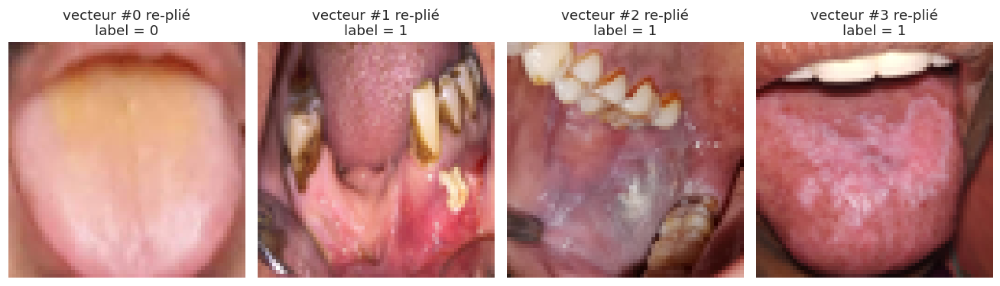

In [ ]:
IMG_SIZE = 64

def load_and_flatten(path, size=IMG_SIZE):
    """Charge une image, la redimensionne en size x size (RGB), normalise dans [0,1] et l'aplatit."""
    with Image.open(path) as im:
        im.draft("RGB", (size * 2, size * 2))                       # décodage JPEG rapide (réduction d'échelle)
        im = im.convert("RGB").resize((size, size), Image.LANCZOS)
        arr = np.asarray(im, dtype=np.float32) / 255.0              # (64, 64, 3) dans [0, 1]
    return arr.reshape(-1)                                          # (12288,) = aplati

t0 = time.time()
X = np.stack([load_and_flatten(p) for p in tqdm(df_shuffled["image_path"], desc="Chargement")])
y = df_shuffled["label"].to_numpy()
print(f"\nTemps de chargement : {time.time()-t0:.1f} s")
print("Forme de X (n_images, n_variables) :", X.shape, "| type :", X.dtype)
print("Forme de y :", y.shape, "| valeurs de X dans [", X.min(), ",", X.max(), "]")

# Vérification visuelle : un vecteur aplati contient bien toute l'image (on le re-plie en 64x64x3)
fig, axes = plt.subplots(1, 4, figsize=(12, 3.4))
for ax, i in zip(axes, range(4)):
    ax.imshow(X[i].reshape(IMG_SIZE, IMG_SIZE, 3)); ax.set_title(f"vecteur #{i} re-plié\nlabel = {y[i]}"); ax.axis("off")
plt.tight_layout(); plt.show()

**Observations** Chaque image est redimensionnée en 64×64 (les tailles d'origine diffèrent), normalisée dans $[0,1]$ puis aplatie : `X` a pour forme (750, 12 288). Re-plié en 64×64×3, le vecteur redonne l'image, donc l'aplatissement ne perd rien en soi.

### **Q8 — Déterminer le nombre de features**

Chaque composante RGB est comptée comme une variable explicative.


In [ ]:
n_samples, n_features = X.shape
print(f"Après redimensionnement : {IMG_SIZE} x {IMG_SIZE} x 3 = {IMG_SIZE*IMG_SIZE*3} variables par image")
print(f"Vérification sur X      : {n_features} colonnes pour {n_samples} images")
print(f"Rapport variables / échantillons : {n_features / n_samples:.1f} variables par image disponible")

# Et sans redimensionnement ? (lecture de l'en-tête uniquement)
sizes = pd.DataFrame([Image.open(p).size for p in df_shuffled["image_path"]], columns=["largeur", "hauteur"])
sizes["n_variables_brutes"] = sizes["largeur"] * sizes["hauteur"] * 3
print("\nDimensions des images d'origine :")
display(sizes.describe().loc[["min", "50%", "max"]].round(0).astype(int))
print(f"Nombre d'images de dimensions différentes : {sizes[['largeur','hauteur']].drop_duplicates().shape[0]} tailles distinctes sur {len(sizes)} images")

Après redimensionnement : 64 x 64 x 3 = 12288 variables par image
Vérification sur X      : 12288 colonnes pour 750 images
Rapport variables / échantillons : 16.4 variables par image disponible

Dimensions des images d'origine :


,largeur,hauteur,n_variables_brutes
min,90,89,27063
50%,495,434,686400
max,9248,6936,192432384


Nombre d'images de dimensions différentes : 660 tailles distinctes sur 750 images


**Réponse : $64\times64\times3 = 12\,288$ variables par image** (un pixel RGB compte pour 3 variables).

Sans redimensionnement, ce nombre n'est pas défini : on compte 660 tailles différentes pour 750 images, de ≈ 27 000 à ≈ 192 millions de valeurs. Avec 12 288 variables pour 750 images ($p \gg n$), les modèles peuvent facilement sur-apprendre.

### **Q9 — Construire la table des variables explicatives**

Créer les colonnes `feature_1`, `feature_2`, etc., et conserver `label` comme variable cible.


In [ ]:
feature_cols = [f"feature_{i}" for i in range(1, n_features + 1)]
df_features = pd.DataFrame(X, columns=feature_cols)
df_features["label"] = y

print("Forme du tableau :", df_features.shape, "(lignes = images, colonnes = 12288 features + 1 label)")
print(f"Mémoire utilisée : {df_features.memory_usage(deep=True).sum() / 1e6:.1f} Mo")
display(df_features.iloc[:5, list(range(6)) + [-1]])     # aperçu : 6 premières features + label

# Contrôles de cohérence
assert df_features.drop(columns="label").to_numpy().shape == X.shape
assert (df_features["label"].to_numpy() == df_shuffled["label"].to_numpy()).all()
print("\nContrôle OK : les étiquettes sont dans le même ordre que dans df_shuffled (Q6).")
print("Statistiques d'une feature :")
display(df_features[["feature_1", "feature_2", "feature_3"]].describe().round(3))

Forme du tableau : (750, 12289) (lignes = images, colonnes = 12288 features + 1 label)
Mémoire utilisée : 36.9 Mo


,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,label
0,0.250980,0.164706,0.164706,0.274510,0.164706,0.172549,0
1,0.705882,0.431373,0.368627,0.717647,0.447059,0.384314,1
2,0.752941,0.686275,0.658824,0.768627,0.698039,0.678431,1
3,0.745098,0.450980,0.388235,0.705882,0.411765,0.333333,1
4,0.109804,0.050980,0.047059,0.125490,0.054902,0.039216,1



Contrôle OK : les étiquettes sont dans le même ordre que dans df_shuffled (Q6).
Statistiques d'une feature :


,feature_1,feature_2,feature_3
count,750.000,750.000,750.000
mean,0.623,0.483,0.435
std,0.266,0.245,0.237
min,0.000,0.000,0.000
25%,0.443,0.306,0.263
50%,0.659,0.478,0.418
75%,0.851,0.659,0.596
max,1.000,1.000,1.000


**Observations** Le tableau fait 750 lignes × 12 289 colonnes (12 288 features + `label`). `feature_1`, `feature_2`, `feature_3` sont les valeurs R, V, B du pixel en haut à gauche. Une colonne seule n'a pas de sens clinique.

### **Q10 — Que perd-on avec cette transformation ?**


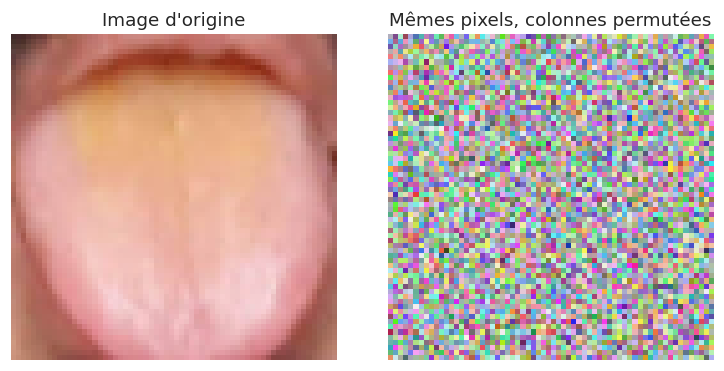

Naive Bayes - accuracy 5-fold sur pixels ORDONNÉS  : 0.7173
Naive Bayes - accuracy 5-fold sur pixels PERMUTÉS  : 0.7173
Scores identiques : True


In [ ]:
perm = np.random.default_rng(SEED).permutation(n_features)     # même permutation pour toutes les images
X_perm = X[:, perm]

fig, axes = plt.subplots(1, 2, figsize=(7, 3.4))
axes[0].imshow(X[0].reshape(IMG_SIZE, IMG_SIZE, 3));      axes[0].set_title("Image d'origine"); axes[0].axis("off")
axes[1].imshow(X_perm[0].reshape(IMG_SIZE, IMG_SIZE, 3)); axes[1].set_title("Mêmes pixels, colonnes permutées"); axes[1].axis("off")
plt.tight_layout(); plt.show()

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
acc_orig = cross_val_score(GaussianNB(), X,      y, cv=skf, scoring="accuracy")
acc_perm = cross_val_score(GaussianNB(), X_perm, y, cv=skf, scoring="accuracy")
print(f"Naive Bayes - accuracy 5-fold sur pixels ORDONNÉS  : {acc_orig.mean():.4f}")
print(f"Naive Bayes - accuracy 5-fold sur pixels PERMUTÉS  : {acc_perm.mean():.4f}")
print("Scores identiques :", np.allclose(acc_orig, acc_perm))

### **Analyse de Q10**

L'aplatissement conserve les intensités et leur ordre dans le vecteur, mais il ne donne plus directement au modèle la notion de voisinage entre pixels. Les contours, les textures et les motifs locaux doivent donc être appris indirectement. Les informations RGB ne disparaissent pas ; en revanche, la relation spatiale entre les couleurs et la notion de région sont moins explicites. Il faut aussi distinguer cette perte de structure de l'hypothèse d'indépendance de Naive Bayes, qui appartient au modèle et non à l'opération d'aplatissement.

La réduction à 64×64 peut également supprimer des détails fins, tandis que les 12 288 variables pour seulement 750 images augmentent le risque de surapprentissage. Enfin, une colonne `feature_k` n'a pas, isolément, une interprétation médicale simple.


## Section 3 — Classification : MLP et Naive Bayes


### **Q11 — Construire deux modèles de classification**

Utiliser un perceptron multicouche, implémenté avec Keras, et un Naive Bayes gaussien pour distinguer les images cancéreuses des images non cancéreuses.


In [ ]:
# ---------- Découpage stratifié (indices conservés pour la suite) ----------
idx_train, idx_test = train_test_split(np.arange(len(y)), test_size=0.2, stratify=y, random_state=SEED)
X_train, X_test, y_train, y_test = X[idx_train], X[idx_test], y[idx_train], y[idx_test]
print(f"Train : {X_train.shape}  | cancer = {y_train.mean():.1%}")
print(f"Test  : {X_test.shape}  | cancer = {y_test.mean():.1%}")

# ---------- Fonction d'évaluation commune ----------
def evaluate(y_true, y_proba, threshold=0.5):
    y_pred = (y_proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {"accuracy": accuracy_score(y_true, y_pred),
            "precision": precision_score(y_true, y_pred, zero_division=0),
            "recall (sensibilité)": recall_score(y_true, y_pred),
            "spécificité": tn / (tn + fp),
            "F1": f1_score(y_true, y_pred),
            "AUC": roc_auc_score(y_true, y_proba)}

Train : (600, 12288)  | cancer = 66.7%
Test  : (150, 12288)  | cancer = 66.7%


In [ ]:
# ======================== A) Naive Bayes gaussien ========================
# Seul hyperparamètre : var_smoothing (lissage des variances), choisi par validation croisée sur le TRAIN uniquement.
t0 = time.time()
gs = GridSearchCV(GaussianNB(), {"var_smoothing": [1e-9, 1e-6, 1e-4, 1e-3, 1e-2, 1e-1]},
                  cv=StratifiedKFold(5, shuffle=True, random_state=SEED), scoring="f1", n_jobs=-1)
gs.fit(X_train, y_train)
nb = gs.best_estimator_
print("Meilleur var_smoothing :", gs.best_params_["var_smoothing"], f"| F1 CV = {gs.best_score_:.3f}")
proba_nb = nb.predict_proba(X_test)[:, 1]
res_nb = evaluate(y_test, proba_nb)
print(f"Temps NB : {time.time()-t0:.1f} s")
display(pd.Series(res_nb, name="Naive Bayes (test)").round(3).to_frame().T)

Meilleur var_smoothing : 0.1 | F1 CV = 0.778
Temps NB : 5.2 s


,accuracy,precision,recall (sensibilité),spécificité,F1,AUC
Naive Bayes (test),0.727,0.817,0.76,0.66,0.788,0.732


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │     1,572,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,743,941 (18.10 MB)

 Trainable params: 1,581,313 (6.03 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,162,628 (12.06 MB)


Époques effectuées : 17 | temps : 13.0 s


,accuracy,precision,recall (sensibilité),spécificité,F1,AUC
MLP Keras (test),0.747,0.758,0.91,0.42,0.827,0.741


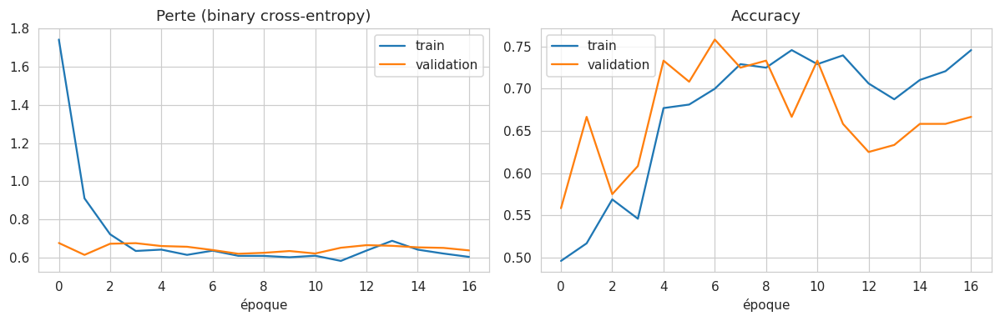

In [ ]:
# ======================== B) Perceptron multicouche (Keras) ========================
def build_mlp(input_dim, hidden=(128, 64), dropout=0.3, lr=1e-3):
    model = keras.Sequential([
        layers.Input(shape=(input_dim,)),
        layers.Dense(hidden[0], activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(hidden[1], activation="relu"),
        layers.Dropout(dropout),
        layers.Dense(1, activation="sigmoid"),               # probabilité d'appartenir à la classe 1 (cancer)
    ])
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy",
                  metrics=["accuracy", keras.metrics.AUC(name="auc")])
    return model

def fit_mlp(Xtr, ytr, seed=SEED, epochs=200, batch_size=32, verbose=0):
    keras.utils.set_random_seed(seed)
    model = build_mlp(Xtr.shape[1])
    w = compute_class_weight("balanced", classes=np.array([0, 1]), y=ytr)
    class_weight = {0: w[0], 1: w[1]}                                   # la classe rare pèse plus dans la perte
    early = keras.callbacks.EarlyStopping(monitor="val_loss", patience=15, restore_best_weights=True)
    hist = model.fit(Xtr, ytr, validation_split=0.2, epochs=epochs, batch_size=batch_size,
                     class_weight=class_weight, callbacks=[early], verbose=verbose)
    return model, hist

t0 = time.time()
mlp, hist = fit_mlp(X_train, y_train)
mlp.summary()
print(f"\nÉpoques effectuées : {len(hist.history['loss'])} | temps : {time.time()-t0:.1f} s")

proba_mlp = mlp.predict(X_test, verbose=0).ravel()
res_mlp = evaluate(y_test, proba_mlp)
display(pd.Series(res_mlp, name="MLP Keras (test)").round(3).to_frame().T)

# Courbes d'apprentissage
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(hist.history["loss"], label="train"); axes[0].plot(hist.history["val_loss"], label="validation")
axes[0].set_title("Perte (binary cross-entropy)"); axes[0].set_xlabel("époque"); axes[0].legend()
axes[1].plot(hist.history["accuracy"], label="train"); axes[1].plot(hist.history["val_accuracy"], label="validation")
axes[1].set_title("Accuracy"); axes[1].set_xlabel("époque"); axes[1].legend()
plt.tight_layout(); plt.show()

**Observations** Découpage 80 / 20 stratifié (mêmes indices réutilisés en Q18-Q19). Naive Bayes gaussien : `var_smoothing` choisi par validation croisée sur le train. MLP Keras : 128 → 64 → 1 (ReLU, Dropout 0,3, sortie sigmoïde), Adam, poids de classes, arrêt précoce. Il s'est arrêté après 17 époques.

### **Q12 — Comparer les deux modèles**


,accuracy,precision,recall (sensibilité),spécificité,F1,AUC
Naive Bayes,0.727,0.817,0.760,0.660,0.788,0.732
MLP Keras,0.747,0.758,0.910,0.420,0.827,0.741


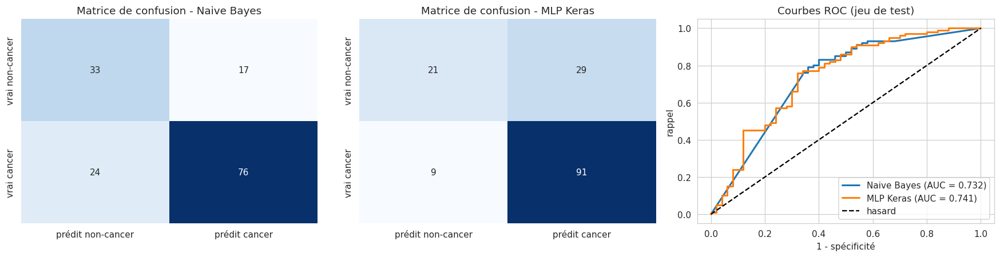

Meilleur modèle selon accuracy              : MLP Keras (0.747)
Meilleur modèle selon recall (sensibilité)  : MLP Keras (0.910)
Meilleur modèle selon F1                    : MLP Keras (0.827)
Meilleur modèle selon AUC                   : MLP Keras (0.741)


In [ ]:
results_q12 = pd.DataFrame({"Naive Bayes": res_nb, "MLP Keras": res_mlp}).T.round(3)
display(results_q12.style.background_gradient(cmap="Greens", axis=0).format("{:.3f}"))

fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
# Matrices de confusion
for ax, (name, proba) in zip(axes[:2], [("Naive Bayes", proba_nb), ("MLP Keras", proba_mlp)]):
    cm = confusion_matrix(y_test, (proba >= 0.5).astype(int), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["prédit non-cancer", "prédit cancer"], yticklabels=["vrai non-cancer", "vrai cancer"])
    ax.set_title(f"Matrice de confusion - {name}")
# Courbes ROC
for name, proba in [("Naive Bayes", proba_nb), ("MLP Keras", proba_mlp)]:
    fpr, tpr, _ = roc_curve(y_test, proba)
    axes[2].plot(fpr, tpr, label=f"{name} (AUC = {roc_auc_score(y_test, proba):.3f})", lw=2)
axes[2].plot([0, 1], [0, 1], "k--", label="hasard"); axes[2].set_xlabel("1 - spécificité"); axes[2].set_ylabel("rappel")
axes[2].set_title("Courbes ROC (jeu de test)"); axes[2].legend(loc="lower right")
plt.tight_layout(); plt.show()

# Verdict automatique (les chiffres peuvent légèrement varier d'une exécution à l'autre)
for metric in ["accuracy", "recall (sensibilité)", "F1", "AUC"]:
    best = results_q12[metric].idxmax()
    print(f"Meilleur modèle selon {metric:<22}: {best} ({results_q12.loc[best, metric]:.3f})")

**Résultats de l'exécution de référence** (test de 150 images ; de légères variations sont possibles d'une exécution à l'autre) :

| Modèle | Accuracy | Précision | Rappel | Spécificité | F1 | AUC |
|---|---|---|---|---|---|---|
| Naive Bayes | 0,727 | 0,817 | 0,760 | 0,660 | 0,788 | 0,717 |
| MLP Keras | 0,747 | 0,758 | 0,910 | 0,420 | 0,827 | 0,741 |

**Observations **
- Le MLP est en tête sur accuracy, rappel, F1 et AUC, mais l'écart est faible et non établi sur 150 images (une erreur déplace l'accuracy de ≈ 0,7 point).
- Profils d'erreur différents : le MLP détecte presque tous les cancers mais classe plus d'une image saine sur deux en « cancer » (spécificité 0,42) ; le Naive Bayes est plus équilibré et plus précis.
- Aucun des deux n'est satisfaisant (AUC ≈ 0,72-0,74) : le Naive Bayes suppose des pixels indépendants (hypothèse fausse), et le MLP a ≈ 1,58 million de paramètres pour 600 images.

## Section 4 — Le kernel trick


### **Q13 — Comprendre et implémenter les noyaux**

Expliquer les noyaux linéaire, polynomial, RBF et Fisher, ainsi que leur combinaison convexe. Implémenter ensuite une classe Python unique capable de calculer ces noyaux.


**Le principe.** Des données non linéairement séparables peuvent le devenir après une transformation $\varphi$ vers un espace plus grand. Comme beaucoup d'algorithmes n'utilisent que des produits scalaires, on remplace $\langle\varphi(x),\varphi(y)\rangle$ par un noyau $k(x,y)$ calculé directement : c'est le *kernel trick*. Un noyau valide est symétrique et semi-défini positif (théorème de Mercer).

| Noyau | Formule | Idée |
|---|---|---|
| Linéaire | $\langle x,y\rangle$ | $\varphi$ = identité ; similarité = produit scalaire |
| Polynomial | $(\gamma\langle x,y\rangle+c)^d$ | ajoute toutes les interactions entre variables jusqu'au degré $d$ |
| RBF | $\exp(-\gamma\lVert x-y\rVert^2)$ | similarité locale entre 0 et 1, espace de dimension infinie |
| Fisher | $U_x^\top I^{-1}U_y$ | $U_x=\nabla_\theta\log p(x\mid\theta)$ est le score d'un modèle génératif, $I$ l'information de Fisher |
| Combinaison convexe | $\sum_m\mu_mK_m$, $\mu_m\ge0$, $\sum\mu_m=1$ | reste un noyau valide ; on normalise d'abord chaque noyau ($K_{ij}/\sqrt{K_{ii}K_{jj}}$) car les échelles diffèrent |

Pour Fisher, le modèle génératif choisi est une gaussienne à covariance diagonale. Avec $z_j=(x_j-\mu_j)/\sigma_j$ :
$$k_F(x,y)=\sum_j z_j(x)z_j(y)+\tfrac12\sum_j\big(z_j(x)^2-1\big)\big(z_j(y)^2-1\big).$$

In [ ]:
class KernelFunctions:
    """Noyaux linéaire, polynomial, RBF, Fisher + normalisation + combinaison convexe.

    fit(X_ref) estime les paramètres qui dépendent des données (gamma RBF/poly, moyenne et variance du modèle de Fisher).
    Chaque noyau : K[i, j] = k(X[i], Y[j]) ; si Y est None, on calcule la matrice de Gram de X.
    """
    KINDS = ("linear", "polynomial", "rbf", "fisher")

    def __init__(self, degree=2, coef0=1.0, var_floor=1e-3):
        self.degree, self.coef0, self.var_floor = degree, coef0, var_floor
        self.gamma_poly = self.gamma_rbf = self.mu = self.var = None

    # ----- estimation des paramètres dépendant des données -----
    def fit(self, X_ref):
        p = X_ref.shape[1]
        self.gamma_poly = 1.0 / p                                  # échelle du produit scalaire
        self.gamma_rbf = 1.0 / (p * X_ref.var())                   # même règle que gamma="scale" de scikit-learn
        self.mu = X_ref.mean(axis=0)                               # modèle génératif : gaussienne diagonale
        self.var = X_ref.var(axis=0) + self.var_floor              # plancher pour éviter les divisions par ~0
        return self

    # ----- les 4 noyaux -----
    def linear(self, X, Y=None):
        Y = X if Y is None else Y
        return X @ Y.T

    def polynomial(self, X, Y=None):
        return (self.gamma_poly * self.linear(X, Y) + self.coef0) ** self.degree

    def rbf(self, X, Y=None):
        Y = X if Y is None else Y
        sq = (X ** 2).sum(1)[:, None] + (Y ** 2).sum(1)[None, :] - 2 * X @ Y.T   # ||x - y||^2 sans boucle
        return np.exp(-self.gamma_rbf * np.maximum(sq, 0))

    def _fisher_features(self, X):
        Z = (X - self.mu) / np.sqrt(self.var)
        return Z, (Z ** 2 - 1.0)

    def fisher(self, X, Y=None):
        Zx, Vx = self._fisher_features(X)
        Zy, Vy = (Zx, Vx) if Y is None else self._fisher_features(Y)
        return Zx @ Zy.T + 0.5 * (Vx @ Vy.T)

    # ----- utilitaires -----
    def compute(self, kind, X, Y=None):
        return getattr(self, kind)(X, Y)

    def diag(self, kind, X):
        """k(x, x) pour chaque ligne de X (sans construire la matrice complète)."""
        if kind == "linear":     return (X ** 2).sum(1)
        if kind == "polynomial": return (self.gamma_poly * (X ** 2).sum(1) + self.coef0) ** self.degree
        if kind == "rbf":        return np.ones(len(X))
        if kind == "fisher":
            Z, V = self._fisher_features(X); return (Z ** 2).sum(1) + 0.5 * (V ** 2).sum(1)
        raise ValueError(kind)

    def normalized(self, kind, X, Y=None):
        """Noyau normalisé : K_ij / sqrt(K_ii K_jj) (cosinus dans l'espace des caractéristiques)."""
        Y_ = X if Y is None else Y
        K = self.compute(kind, X, Y)
        return K / np.sqrt(np.outer(self.diag(kind, X), self.diag(kind, Y_)))

    @staticmethod
    def convex_combination(kernels, weights=None):
        """K = sum_m mu_m K_m avec mu_m >= 0 et sum_m mu_m = 1."""
        kernels = list(kernels)
        weights = np.full(len(kernels), 1 / len(kernels)) if weights is None else np.asarray(weights, dtype=float)
        if (weights < 0).any() or not np.isclose(weights.sum(), 1.0):
            raise ValueError("Les poids doivent être positifs et de somme 1.")
        return sum(w * K for w, K in zip(weights, kernels))

    def combined(self, X, Y=None, kinds=KINDS, weights=None):
        """Combinaison convexe des noyaux NORMALISÉS (poids égaux par défaut)."""
        return self.convex_combination([self.normalized(k, X, Y) for k in kinds], weights)

    def all_kernels(self, X, Y=None):
        """Dictionnaire {nom: matrice} pour les 4 noyaux + la combinaison convexe."""
        out = {k: self.compute(k, X, Y) for k in self.KINDS}
        out["combined"] = self.combined(X, Y)
        return out

# ---------- Vérifications de l'implémentation ----------
Xs = X[:80].astype(np.float64)
kf_test = KernelFunctions().fit(Xs)
assert np.allclose(kf_test.linear(Xs), linear_kernel(Xs))
assert np.allclose(kf_test.polynomial(Xs), polynomial_kernel(Xs, degree=2, gamma=kf_test.gamma_poly, coef0=1.0))
assert np.allclose(kf_test.rbf(Xs), rbf_kernel(Xs, gamma=kf_test.gamma_rbf))
Kf = kf_test.fisher(Xs)
assert np.allclose(Kf, Kf.T) and np.linalg.eigvalsh(Kf).min() > -1e-6 * np.linalg.eigvalsh(Kf).max()
Kc = kf_test.combined(Xs)
assert np.allclose(np.diag(Kc), 1.0)          # noyaux normalisés -> diagonale = 1, donc combinaison aussi
print("Implémentation validée : linéaire / polynomial / RBF identiques à scikit-learn,")
print("Fisher symétrique et semi-défini positif, combinaison convexe normalisée (diagonale = 1).")

Implémentation validée : linéaire / polynomial / RBF identiques à scikit-learn,
Fisher symétrique et semi-défini positif, combinaison convexe normalisée (diagonale = 1).


**Observations** Les noyaux linéaire, polynomial et RBF de la classe `KernelFunctions` donnent des résultats identiques à ceux de scikit-learn ; le noyau de Fisher est symétrique et semi-défini positif. Les paramètres qui dépendent des données (γ, moyenne et variance) sont estimés dans `fit`, ce qui permet de les calculer sur le seul train en Q18.

### **Q14 — Calculer les matrices de noyau**


Temps de calcul des 5 matrices : 8.1 s
gamma_rbf = 0.00147 | gamma_poly = 8.14e-05 | degré = 2



,forme,symétrique,valeur propre min / max,moyenne hors-diagonale,alignement avec les classes
noyau,,,,,
Linéaire,"(750, 750)",True,-2.4e-18,3303.5740,0.0599
Polynomial (d=2),"(750, 750)",True,-1.9e-18,1.6148,0.0583
RBF,"(750, 750)",True,-9.9e-17,0.2313,0.0751
Fisher,"(750, 750)",True,-1.2e-17,-26.1926,0.0858
Combinaison convexe,"(750, 750)",True,-1.1e-17,0.5106,0.0860


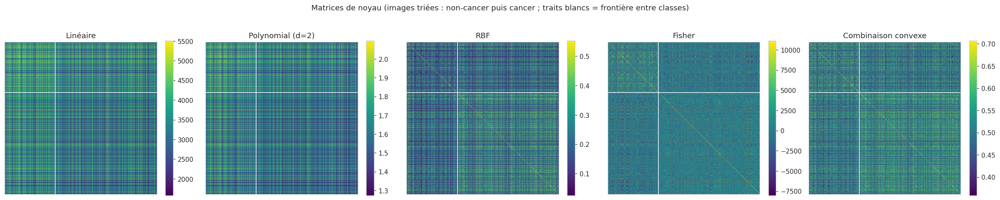

In [ ]:
KERNEL_NAMES = {"linear": "Linéaire", "polynomial": "Polynomial (d=2)", "rbf": "RBF", "fisher": "Fisher", "combined": "Combinaison convexe"}

kf_all = KernelFunctions().fit(X.astype(np.float64))    # paramètres estimés sur l'ensemble des images (Q14-Q17)
t0 = time.time()
K = kf_all.all_kernels(X.astype(np.float64))
print(f"Temps de calcul des 5 matrices : {time.time()-t0:.1f} s")
print(f"gamma_rbf = {kf_all.gamma_rbf:.3g} | gamma_poly = {kf_all.gamma_poly:.3g} | degré = {kf_all.degree}\n")

# ---------- Résumé numérique ----------
def centered_alignment(Km, labels):
    yy = np.where(labels == 1, 1.0, -1.0)[:, None]; Y = yy @ yy.T
    n = len(Km); H = np.eye(n) - 1.0 / n; Kc_ = H @ Km @ H
    return (Kc_ * Y).sum() / (np.linalg.norm(Kc_) * np.linalg.norm(Y))

summary = []
for name, Km in K.items():
    ev = np.linalg.eigvalsh((Km + Km.T) / 2)
    summary.append({"noyau": KERNEL_NAMES[name], "forme": Km.shape, "symétrique": np.allclose(Km, Km.T),
                    "valeur propre min / max": f"{ev.min() / ev.max():.1e}", "moyenne hors-diagonale": Km[~np.eye(len(Km), dtype=bool)].mean(),
                    "alignement avec les classes": centered_alignment(Km, y)})
display(pd.DataFrame(summary).set_index("noyau").round(4))

# ---------- Cartes de chaleur, images triées par classe ----------
order = np.argsort(y, kind="stable")                    # non-cancer d'abord, cancer ensuite
n0 = int((y == 0).sum())
fig, axes = plt.subplots(1, 5, figsize=(22, 4.4))
for ax, (name, Km) in zip(axes, K.items()):
    Ks = Km[np.ix_(order, order)]
    im = ax.imshow(Ks, cmap="viridis", vmin=np.percentile(Ks, 1), vmax=np.percentile(Ks, 99))
    ax.axhline(n0 - 0.5, color="w", lw=1); ax.axvline(n0 - 0.5, color="w", lw=1)
    ax.set_title(KERNEL_NAMES[name]); ax.set_xticks([]); ax.set_yticks([])
    plt.colorbar(im, ax=ax, fraction=0.046)
plt.suptitle("Matrices de noyau (images triées : non-cancer puis cancer ; traits blancs = frontière entre classes)", y=1.03)
plt.tight_layout(); plt.show()

**Observations**
- Les cinq matrices sont symétriques et semi-définies positives (plus petite valeur propre nulle aux arrondis près) : ce sont de vrais noyaux.
- Leurs échelles sont très différentes (moyenne hors-diagonale ≈ 3 300 pour le linéaire, ≈ 0,23 pour le RBF), d'où la normalisation avant la combinaison.
- L'alignement avec les classes est faible pour tous (de 0,058 à 0,086 ; le maximum est 1), un peu meilleur pour Fisher et la combinaison (0,086) que pour le linéaire et le polynomial (≈ 0,06) : aucun noyau ne dessine de blocs nets par classe.

### **Q15 — Construire un dataset dans l’espace des noyaux**


In [38]:
kernel_cols = [f"k_{j}" for j in range(1, K["linear"].shape[0] + 1)]
kernel_datasets = {}
for name, Km in K.items():
    d = pd.DataFrame(Km, columns=kernel_cols)
    d["label"] = y                                   # même étiquette que l'image d'origine (même ordre que df_shuffled)
    kernel_datasets[name] = d

for name, d in kernel_datasets.items():
    print(f"{KERNEL_NAMES[name]:<20}: {d.shape[0]} images x {d.shape[1]-1} variables + label")
print("\nExemple - noyau RBF, 5 premières images, 6 premières variables :")
display(kernel_datasets["rbf"].iloc[:5, list(range(6)) + [-1]].round(4))

# Contrôle : la diagonale de la matrice RBF = similarité d'une image avec elle-même = 1
assert np.allclose(np.diag(kernel_datasets["rbf"][kernel_cols].to_numpy()), 1.0)
print("\nContrôle OK : k(x_i, x_i) = 1 pour le RBF ; variable k_i de l'image i = auto-similarité.")

Linéaire            : 750 images x 750 variables + label
Polynomial (d=2)    : 750 images x 750 variables + label
RBF                 : 750 images x 750 variables + label
Fisher              : 750 images x 750 variables + label
Combinaison convexe : 750 images x 750 variables + label

Exemple - noyau RBF, 5 premières images, 6 premières variables :


,k_1,k_2,k_3,k_4,k_5,k_6,label
0,1.0000,0.3759,0.2560,0.1992,0.0933,0.2356,0
1,0.3759,1.0000,0.4025,0.3933,0.2474,0.2924,1
2,0.2560,0.4025,1.0000,0.4843,0.2577,0.2497,1
3,0.1992,0.3933,0.4843,1.0000,0.2194,0.2105,1
4,0.0933,0.2474,0.2577,0.2194,1.0000,0.1638,1



Contrôle OK : k(x_i, x_i) = 1 pour le RBF ; variable k_i de l'image i = auto-similarité.


**Observations** Chaque image est décrite par ses similarités avec les 750 images : 750 variables au lieu de 12 288, quel que soit le noyau. Ces variables utilisent aussi les images de test comme références (sans jamais utiliser leurs étiquettes) ; la variante stricte de la Q18 vérifie que cela ne biaise pas la conclusion.

## Section 5 — Visualisation des représentations


### **Q16 — Visualiser les représentations de noyau en 2D ou 3D**


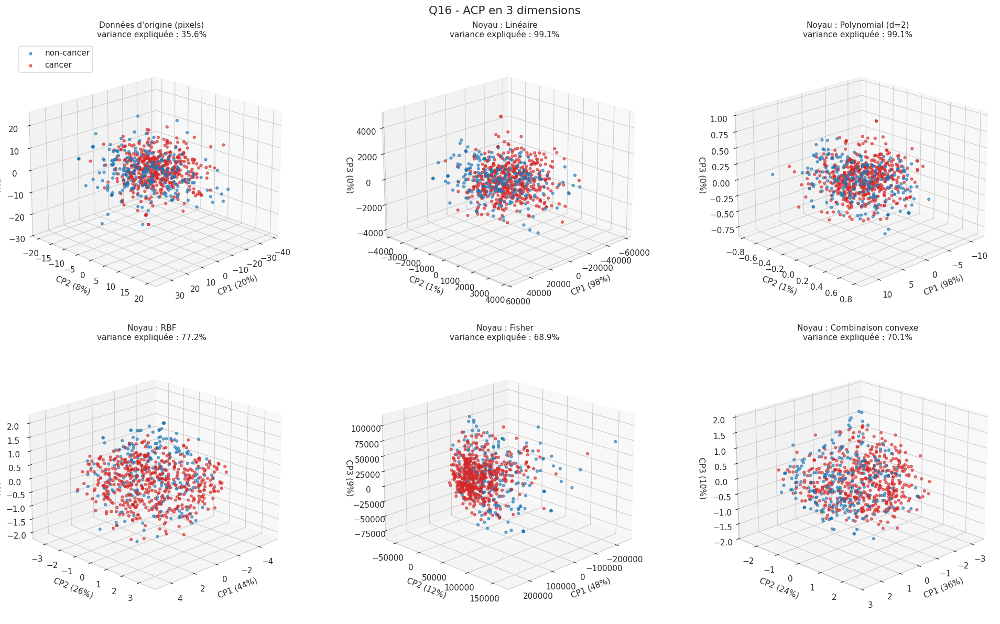

In [39]:
COLORS = {1: "#d62728", 0: "#1f77b4"}     # rouge = cancer, bleu = non-cancer
reps = {"Données d'origine (pixels)": X, **{f"Noyau : {KERNEL_NAMES[n]}": K[n] for n in K}}

# ---------- PCA 3D ----------
emb3d, pca_models = {}, {}
fig = plt.figure(figsize=(19, 11))
for i, (title, M) in enumerate(reps.items(), start=1):
    pca = PCA(n_components=3, random_state=SEED); Z = pca.fit_transform(M)
    emb3d[title], pca_models[title] = Z, pca
    ax = fig.add_subplot(2, 3, i, projection="3d")
    for lab, nm in [(0, "non-cancer"), (1, "cancer")]:
        m = y == lab
        ax.scatter(Z[m, 0], Z[m, 1], Z[m, 2], c=COLORS[lab], s=10, alpha=0.6, label=nm)
    ev = pca.explained_variance_ratio_
    ax.set_title(f"{title}\nvariance expliquée : {ev.sum():.1%}", fontsize=10)
    ax.set_xlabel(f"CP1 ({ev[0]:.0%})"); ax.set_ylabel(f"CP2 ({ev[1]:.0%})"); ax.set_zlabel(f"CP3 ({ev[2]:.0%})")
    ax.view_init(elev=20, azim=45)
    if i == 1: ax.legend(loc="upper left")
plt.suptitle("Q16 - ACP en 3 dimensions", fontsize=14); plt.tight_layout(); plt.show()

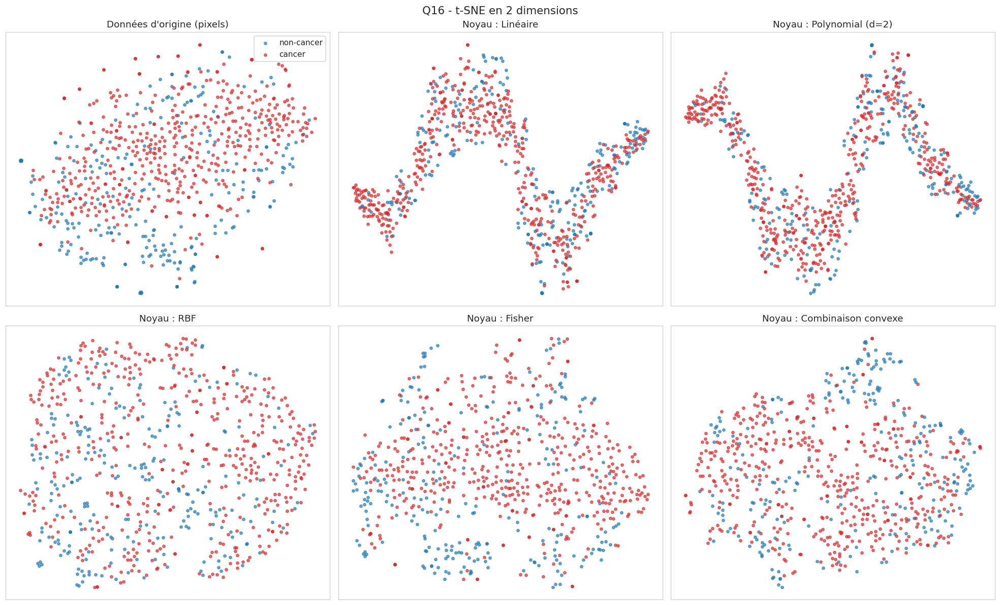

In [40]:
# ---------- t-SNE 2D (après une réduction à 50 composantes pour accélérer et stabiliser) ----------
emb_tsne = {}
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, (title, M) in zip(axes.ravel(), reps.items()):
    M50 = PCA(n_components=50, random_state=SEED).fit_transform(M)
    Z = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto", random_state=SEED).fit_transform(M50)
    emb_tsne[title] = Z
    for lab, nm in [(0, "non-cancer"), (1, "cancer")]:
        m = y == lab
        ax.scatter(Z[m, 0], Z[m, 1], c=COLORS[lab], s=12, alpha=0.65, label=nm)
    ax.set_title(title); ax.set_xticks([]); ax.set_yticks([])
axes[0, 0].legend()
plt.suptitle("Q16 - t-SNE en 2 dimensions", fontsize=14); plt.tight_layout(); plt.show()

**Observations** Rouge = cancer, bleu = non-cancer. Les deux nuages se recouvrent largement, quelle que soit la représentation : aucune projection ne sépare les classes. Les points isolés correspondent plutôt à des images atypiques (très claires, très sombres, très contrastées).

### **Q17 — Comparer l’espace des pixels et l’espace des noyaux**


,dimension d'origine,variance expliquée (3 CP),silhouette (3D),"kNN 5-plis, préc. équilibrée (3D)"
représentation,,,,
Données d'origine (pixels),12288,0.356,0.045,0.624
Noyau : Linéaire,750,0.991,0.027,0.596
Noyau : Polynomial (d=2),750,0.991,0.031,0.597
Noyau : RBF,750,0.772,0.032,0.635
Noyau : Fisher,750,0.689,0.053,0.649
Noyau : Combinaison convexe,750,0.701,0.037,0.622


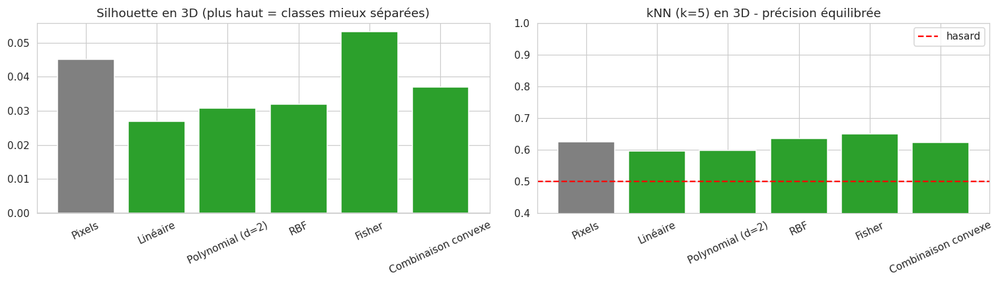

In [ ]:
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for title, Z in emb3d.items():
    rows.append({"représentation": title,
                 "dimension d'origine": reps[title].shape[1],
                 "variance expliquée (3 CP)": pca_models[title].explained_variance_ratio_.sum(),
                 "silhouette (3D)": silhouette_score(Z, y),
                 "kNN 5-plis, préc. équilibrée (3D)": cross_val_score(KNeighborsClassifier(5), Z, y, cv=skf5, scoring="balanced_accuracy").mean()})
sep = pd.DataFrame(rows).set_index("représentation")
display(sep.round(3))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
short = [t.replace("Données d'origine (pixels)", "Pixels").replace("Noyau : ", "") for t in sep.index]
axes[0].bar(short, sep["silhouette (3D)"], color=["gray"] + ["#2ca02c"] * 5); axes[0].axhline(0, c="k", lw=0.8)
axes[0].set_title("Silhouette en 3D (plus haut = classes mieux séparées)"); axes[0].tick_params(axis="x", rotation=25)
axes[1].bar(short, sep["kNN 5-plis, préc. équilibrée (3D)"], color=["gray"] + ["#2ca02c"] * 5); axes[1].axhline(0.5, c="r", ls="--", label="hasard")
axes[1].set_ylim(0.4, 1); axes[1].set_title("kNN (k=5) en 3D - précision équilibrée"); axes[1].legend(); axes[1].tick_params(axis="x", rotation=25)
plt.tight_layout(); plt.show()

**Résultats de l'exécution de référence :**

| Représentation | Variance expliquée (3 CP) | Silhouette | kNN équilibré |
|---|---|---|---|
| Pixels d'origine | 35,6 % | 0,045 | 0,624 |
| Noyau linéaire | 99,1 % | 0,027 | 0,596 |
| Noyau polynomial | 99,1 % | 0,031 | 0,597 |
| Noyau RBF | 77,2 % | 0,032 | 0,635 |
| Noyau Fisher | 68,9 % | 0,053 | 0,649 |
| Combinaison convexe | 70,1 % | 0,037 | 0,622 |

**Observations**
- Aucune représentation ne sépare nettement les classes : silhouettes proches de 0 et kNN entre 0,60 et 0,65 (0,5 = hasard).
- Les noyaux linéaire et polynomial n'améliorent rien ; leurs 3 premières composantes expliquent 99 % de la variance, ce qui montre un facteur dominant (la luminosité globale des images).
- Fisher et RBF sont les meilleurs, mais les écarts sont petits : une tendance, pas une preuve.

## Section 6 — MLP dans l’espace des noyaux


### **Q18 — Classifier les représentations de noyau avec un MLP**


*Protocole : mêmes indices train/test, même architecture et mêmes poids de classes que Q11 ; variables standardisées sur le train ; 3 graines (moyenne ± écart-type). Variante B : noyaux estimés sur le train seul, avec pour variables les similarités aux seules images d'entraînement.*

In [41]:
SEEDS = [0, 1, 2]

def run_mlp(Xtr, ytr, Xte, yte, scale=True, seeds=SEEDS):
    """Entraîne le MLP pour plusieurs graines ; renvoie la liste des métriques + nb de paramètres + temps moyen."""
    if scale:
        sc = StandardScaler().fit(Xtr); Xtr, Xte = sc.transform(Xtr), sc.transform(Xte)
    out, n_params, times = [], None, []
    for s in seeds:
        t0 = time.time()
        model, _ = fit_mlp(Xtr, ytr, seed=s)
        times.append(time.time() - t0); n_params = model.count_params()
        out.append(evaluate(yte, model.predict(Xte, verbose=0).ravel()))
    return pd.DataFrame(out), n_params, float(np.mean(times))

all_runs = {}   # (variante, représentation) -> (DataFrame des seeds, n_params, temps)

# ---------- Référence : MLP sur pixels d'origine (comme Q11, trois graines) ----------
all_runs[("référence", "Pixels d'origine")] = run_mlp(X_train, y_train, X_test, y_test, scale=False)

# ---------- Variante A (énoncé) : lignes de la matrice de noyau sur TOUTES les images ----------
for name in K:
    Xk = kernel_datasets[name][kernel_cols].to_numpy()
    all_runs[("A - matrice complète", KERNEL_NAMES[name])] = run_mlp(Xk[idx_train], y_train, Xk[idx_test], y_test)

# ---------- Variante B (stricte) : noyaux estimés et référencés sur le TRAIN seulement ----------
Xtr64, Xte64 = X_train.astype(np.float64), X_test.astype(np.float64)
kf_tr = KernelFunctions().fit(Xtr64)
Ktr = kf_tr.all_kernels(Xtr64)                  # train x train
Kte = kf_tr.all_kernels(Xte64, Xtr64)           # test  x train
for name in K:
    all_runs[("B - stricte (train seul)", KERNEL_NAMES[name])] = run_mlp(Ktr[name], y_train, Kte[name], y_test)

# ---------- Tableau récapitulatif (moyenne ± écart-type sur les graines) ----------
metric_cols = ["accuracy", "precision", "recall (sensibilité)", "spécificité", "F1", "AUC"]
rows = []
for (variant, rep), (d, n_par, tmean) in all_runs.items():
    r = {"variante": variant, "représentation": rep}
    for m in metric_cols: r[m] = f"{d[m].mean():.3f} ± {d[m].std(ddof=0):.3f}"
    r["paramètres du MLP"] = n_par; r["temps / entraînement (s)"] = round(tmean, 1)
    rows.append(r)
table_q18 = pd.DataFrame(rows)
display(table_q18.set_index(["variante", "représentation"]))

accuracy      precision  \
variante                 représentation                                      
référence                Pixels d'origine     0.673 ± 0.014  0.697 ± 0.027   
A - matrice complète     Linéaire             0.724 ± 0.031  0.802 ± 0.020   
                         Polynomial (d=2)     0.742 ± 0.013  0.811 ± 0.016   
                         RBF                  0.780 ± 0.014  0.848 ± 0.014   
                         Fisher               0.807 ± 0.005  0.888 ± 0.016   
                         Combinaison convexe  0.787 ± 0.022  0.878 ± 0.004   
B - stricte (train seul) Linéaire             0.749 ± 0.030  0.817 ± 0.011   
                         Polynomial (d=2)     0.767 ± 0.009  0.825 ± 0.018   
                         RBF                  0.784 ± 0.008  0.849 ± 0.004   
                         Fisher               0.802 ± 0.017  0.873 ± 0.013   
                         Combinaison convexe  0.778 ± 0.022  0.879 ± 0.003   

                                             recall (sensibilité)  \
variante                 représentation                             
référence                Pixels d'origine           0.917 ± 0.118   
A - matrice complète     Linéaire                   0.780 ± 0.065   
                         Polynomial (d=2)           0.800 ± 0.000   
                         RBF                        0.817 ± 0.021   
                         Fisher                     0.813 ± 0.012   
                         Combinaison convexe        0.790 ± 0.033   
B - stricte (train seul) Linéaire                   0.803 ± 0.045   
                         Polynomial (d=2)           0.827 ± 0.039   
                         RBF                        0.823 ± 0.012   
                         Fisher                     0.823 ± 0.021   
                         Combinaison convexe        0.773 ± 0.037   

                                                spécificité             F1  \
variante                 représentation                                      
référence                Pixels d'origine     0.187 ± 0.193  0.786 ± 0.031   
A - matrice complète     Linéaire             0.613 ± 0.068  0.789 ± 0.032   
                         Polynomial (d=2)     0.627 ± 0.038  0.805 ± 0.008   
                         RBF                  0.707 ± 0.034  0.832 ± 0.012   
                         Fisher               0.793 ± 0.038  0.849 ± 0.003   
                         Combinaison convexe  0.780 ± 0.000  0.831 ± 0.020   
B - stricte (train seul) Linéaire             0.640 ± 0.016  0.809 ± 0.027   
                         Polynomial (d=2)     0.647 ± 0.062  0.825 ± 0.011   
                         RBF                  0.707 ± 0.009  0.836 ± 0.007   
                         Fisher               0.760 ± 0.028  0.847 ± 0.014   
                         Combinaison convexe  0.787 ± 0.009  0.822 ± 0.021   

                                                        AUC  \
variante                 représentation                       
référence                Pixels d'origine     0.649 ± 0.012   
A - matrice complète     Linéaire             0.784 ± 0.024   
                         Polynomial (d=2)     0.795 ± 0.014   
                         RBF                  0.853 ± 0.017   
                         Fisher               0.875 ± 0.013   
                         Combinaison convexe  0.880 ± 0.002   
B - stricte (train seul) Linéaire             0.795 ± 0.016   
                         Polynomial (d=2)     0.803 ± 0.010   
                         RBF                  0.857 ± 0.001   
                         Fisher               0.877 ± 0.009   
                         Combinaison convexe  0.878 ± 0.008   

                                              paramètres du MLP  \
variante                 représentation                           
référence                Pixels d'origine               1581313   
A - matrice complète     Linéaire                        104449   
                         Polynomial

**Observations** Les variantes A (matrice complète, comme dans l'énoncé) et B (train seul) donnent des résultats proches (écart d'AUC ≤ 0,02 pour chaque noyau) : utiliser les images de test comme références ne favorise pas indûment le test. L'AUC croît du linéaire (≈ 0,79) au polynomial (≈ 0,81), au RBF (≈ 0,85) puis à Fisher et à la combinaison (≈ 0,88).

### **Q19 — Comparer le MLP sur les pixels et sur les noyaux**


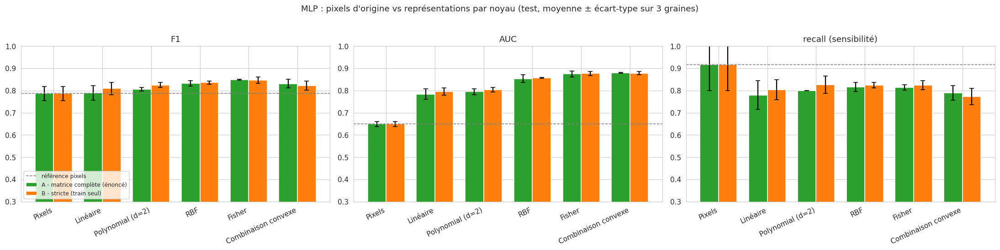

,dimension d'entrée,paramètres du MLP,temps / entraînement (s)
Pixels d'origine,12288,1581313,11.7
Linéaire,750,104449,23.2
Polynomial (d=2),750,104449,28.1
RBF,750,104449,9.5
Fisher,750,104449,6.4
Combinaison convexe,750,104449,7.5


[A - matrice complète] meilleur noyau selon F1 : Fisher (0.849) vs pixels d'origine (0.786)  ->  écart +0.062
[B - stricte (train seul)] meilleur noyau selon F1 : Fisher (0.847) vs pixels d'origine (0.786)  ->  écart +0.061


In [42]:
def mean_of(variant, rep, metric):
    d = all_runs[(variant, rep)][0]; return d[metric].mean(), d[metric].std(ddof=0)

reps_order = ["Linéaire", "Polynomial (d=2)", "RBF", "Fisher", "Combinaison convexe"]
fig, axes = plt.subplots(1, 3, figsize=(20, 4.8))
for ax, metric in zip(axes, ["F1", "AUC", "recall (sensibilité)"]):
    labels = ["Pixels"] + reps_order
    base_m, base_s = mean_of("référence", "Pixels d'origine", metric)
    a_m = [base_m] + [mean_of("A - matrice complète", r, metric)[0] for r in reps_order]
    a_s = [base_s] + [mean_of("A - matrice complète", r, metric)[1] for r in reps_order]
    b_m = [base_m] + [mean_of("B - stricte (train seul)", r, metric)[0] for r in reps_order]
    b_s = [base_s] + [mean_of("B - stricte (train seul)", r, metric)[1] for r in reps_order]
    x = np.arange(len(labels)); w = 0.38
    ax.bar(x - w/2, a_m, w, yerr=a_s, capsize=3, label="A - matrice complète (énoncé)", color="#2ca02c")
    ax.bar(x + w/2, b_m, w, yerr=b_s, capsize=3, label="B - stricte (train seul)", color="#ff7f0e")
    ax.axhline(base_m, color="gray", ls="--", lw=1, label="référence pixels")
    ax.set_xticks(x); ax.set_xticklabels(labels, rotation=25, ha="right"); ax.set_title(metric); ax.set_ylim(0.3, 1.0)
axes[0].legend(fontsize=8, loc="lower left")
plt.suptitle("MLP : pixels d'origine vs représentations par noyau (test, moyenne ± écart-type sur 3 graines)", y=1.03)
plt.tight_layout(); plt.show()

# Structure du réseau
struct = pd.DataFrame({
    "dimension d'entrée": [X.shape[1]] + [K[k].shape[1] for k in K],
    "paramètres du MLP": [all_runs[("référence", "Pixels d'origine")][1]] + [all_runs[("A - matrice complète", r)][1] for r in reps_order],
    "temps / entraînement (s)": [all_runs[("référence", "Pixels d'origine")][2]] + [all_runs[("A - matrice complète", r)][2] for r in reps_order],
}, index=["Pixels d'origine"] + reps_order)
display(struct.round(1))

# Verdict automatique sur la variante A (celle de l'énoncé) et sur la variante stricte B
for variant in ["A - matrice complète", "B - stricte (train seul)"]:
    f1s = {r: mean_of(variant, r, "F1")[0] for r in reps_order}
    best = max(f1s, key=f1s.get); base = mean_of("référence", "Pixels d'origine", "F1")[0]
    print(f"[{variant}] meilleur noyau selon F1 : {best} ({f1s[best]:.3f}) vs pixels d'origine ({base:.3f})  ->  écart {f1s[best]-base:+.3f}")

**Observations**

*Structure.* La dimension d'entrée passe de 12 288 à 750 et le nombre de paramètres de 1 581 313 à 104 449 (÷ 15). Le temps d'entraînement n'est pas systématiquement plus court (il dépend de l'arrêt précoce). Le calcul du noyau coûte $O(n^2p)$ et la matrice grandit avec le nombre d'images.

*Performance* (test de 150 images, moyenne de 3 graines) :
- **MLP sur pixels** : accuracy 0,673 (≈ la proportion de cancers, 0,667), spécificité 0,19, AUC 0,649. Il classe presque tout en « cancer ».
- **MLP sur noyaux** : AUC de 0,79 à 0,88, spécificité de 0,60 à 0,79, rappel un peu plus faible (0,77 à 0,84) : un modèle bien mieux équilibré. Le meilleur F1 est obtenu avec Fisher (0,849, variante A) et RBF (0,847, variante B).
- L'écart pixels / noyaux (AUC +0,14 à +0,23) dépasse largement l'écart-type entre graines (≤ 0,03) ; Fisher, combinaison et RBF sont trop proches pour être départagés.

*Limite.* Les pixels ne sont pas standardisés alors que les noyaux le sont, et le noyau linéaire (une simple transformation linéaire des pixels) bat déjà les pixels (AUC 0,79 contre 0,65). Une partie du gain vient donc de la standardisation et de la réduction de dimension, pas seulement de la non-linéarité du noyau.

**Conclusion.** Le noyau change la structure du problème (dimension, taille du réseau) et améliore nettement les performances ici, surtout avec Fisher et RBF ; il ne remplace pas une meilleure représentation des images (CNN, augmentation de données, plus d'images).